    Configuration  Win_Rate_vs_Random
    Default_Rules            0.933333
   Mobility_Focus            0.933333
 Aggressive_Discs            0.916667
Ablation_NoDanger            0.750000


C:\Users\nhila\AppData\Local\Temp\ipykernel_11688\267418414.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_tune, x="Configuration", y="Win_Rate_vs_Random", palette="Blues_d")


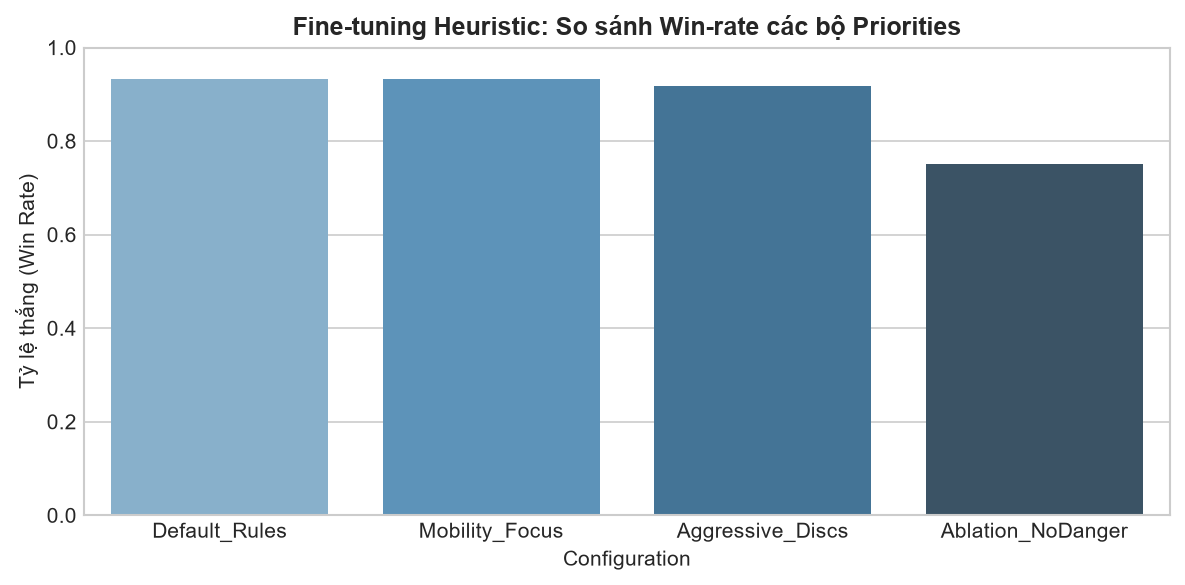

In [ ]:
import sys
import os

# Thêm thư mục gốc dự án (lùi 2 cấp từ notebooks/tune ra Project_final)
sys.path.append(os.path.abspath('../..'))

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from othello.game import OthelloGame
from agents.random_agent import RandomAgent
from agents.heuristic_agent import HeuristicAgent
from agents.alphabeta_agent import AlphaBetaAgent
from agents.mcts_agent import MCTSAgent

# Cấu hình đồ thị cho báo cáo
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 150

def run_tournament(agent1, agent2, num_games=20):
    """Cho 2 Agent thi đấu num_games ván (luân phiên Đen/Trắng).
    Trả về: tỷ lệ thắng của agent1.
    """
    a1_wins, a2_wins, draws = 0, 0, 0
    
    for game_id in range(num_games):
        game = OthelloGame()
        # Đổi bên mỗi ván
        p1, p2 = (agent1, agent2) if game_id % 2 == 0 else (agent2, agent1)
        agent1.reset()
        agent2.reset()
        
        while not game.is_terminal():
            cur = game.current_player
            current_agent = p1 if cur == 1 else p2
            action = current_agent.select_action(game)
            if action is not None:
                game.step(action)
            else:
                game.pass_turn()
                
        # --- CÁCH TÍNH KẾT QUẢ CHUẨN DỰA TRÊN SCORE BÀN CỜ ---
        # Đếm số lượng quân Đen (1) và Trắng (-1) trên bàn cờ
        black_discs = int((game.board == 1).sum())
        white_discs = int((game.board == -1).sum())
        
        # Xác định người chiến thắng: 1 (Đen thắng), -1 (Trắng thắng), 0 (Hòa)
        if black_discs > white_discs:
            winner = 1
        elif white_discs > black_discs:
            winner = -1
        else:
            winner = 0
            
        # Cập nhật kết quả cho agent1
        if winner == 0:
            draws += 1
        elif (winner == 1 and p1 == agent1) or (winner == -1 and p2 == agent1):
            a1_wins += 1
        else:
            a2_wins += 1
            
    win_rate = (a1_wins + 0.5 * draws) / num_games
    return win_rate
# --- THỬ NGHIỆM FINE-TUNING CÁC BỘ TRỌNG SỐ HEURISTIC ---
baseline_opponent = AlphaBetaAgent()

# Các biến thể bộ trọng số / priorities
configs_to_tune = {
    "Default_Rules": ["win_now", "take_corner", "avoid_x_square", "avoid_c_square", "maximize_mobility", "maximize_discs"],
    "Mobility_Focus": ["win_now", "take_corner", "maximize_mobility", "avoid_x_square", "avoid_c_square", "maximize_discs"],
    "Aggressive_Discs": ["win_now", "take_corner", "maximize_discs", "maximize_mobility", "avoid_x_square", "avoid_c_square"],
    "Ablation_NoDanger": ["win_now", "take_corner", "maximize_mobility", "maximize_discs"]
}

tune_results = []
for name, priorities in configs_to_tune.items():
    agent = HeuristicAgent(priorities=priorities)
    wr = run_tournament(agent, baseline_opponent, num_games=30)
    tune_results.append({"Configuration": name, "Win_Rate_vs_Random": wr})

df_tune = pd.DataFrame(tune_results)
print(df_tune.to_string(index=False))

# Trực quan hóa kết quả Fine-tuning Heuristic
plt.figure(figsize=(8, 4))
sns.barplot(data=df_tune, x="Configuration", y="Win_Rate_vs_Random", palette="Blues_d")
plt.title("Fine-tuning Heuristic: So sánh Win-rate các bộ Priorities", fontsize=12, fontweight="bold")
plt.ylim(0, 1.0)
plt.ylabel("Tỷ lệ thắng (Win Rate)")
plt.tight_layout()
plt.show()